# Proyecto: ETc del cultivo por FAO-56

## Doble coeficiente Kc y riego al 50 % TAW

**Curso Data Science en Sistemas Naturales**

Este cuaderno calcula la evapotranspiracion del cultivo (ETc) para un solo escenario con riego, usando el metodo FAO-56 (Allen et al., 1998):

1. ETo por Penman-Monteith FAO-56.
2. Coeficiente doble: Kc = Kcb + Ke (basal + evaporacion del suelo).
3. ETc en condiciones no estandar con coeficiente de estres hidrico Ks:
   - ETc estandar = (Kcb + Ke) * ETo
   - ETc no estandar = (Ks * Kcb + Ke) * ETo
4. Riego: reposicion a capacidad de campo (FC) cuando la deplecion de la zona radicular alcanza el 50 % de TAW.

Cada celda de codigo se ejecuta de forma independiente. Las figuras se embeben en el cuaderno y se pueden exportar como PNG desde el menu de Jupyter.


In [1]:
# CELDA 1 - Importar librerias

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

print('Librerias cargadas correctamente.')


Librerias cargadas correctamente.


In [2]:
# CELDA 2 - Parametros del sitio (ajustables)

LAT = -33.45       # latitud [grados decimales; negativo = hemisferio sur]
Z   = 520.0        # altitud [msnm]
ALBEDO = 0.23      # albedo de la superficie de referencia (cesped FAO-56)

print(f'Sitio: lat={LAT}, altitud={Z} msnm')


Sitio: lat=-33.45, altitud=520.0 msnm


In [3]:
# CELDA 3 - Parametros del cultivo y del suelo

from dataclasses import dataclass

@dataclass
class CropSoil:
    L_ini: int = 25   # etapa inicial
    L_dev: int = 45   # desarrollo
    L_mid: int = 90   # estacion media
    L_end: int = 45   # final de estacion

    Kcb_ini: float = 0.15
    Kcb_mid: float = 1.05
    Kcb_end: float = 0.90

    Ke_max: float = 0.12

    Zr: float = 0.80       # profundidad zona radicular [m]
    th_FC: float = 0.28    # humedad capacidad de campo [m3/m3]
    th_WP: float = 0.13    # punto marchitez permanente [m3/m3]
    th_01: float = 0.10    # humedad a -0.1 bar (para TEW) [m3/m3]
    Ze: float = 0.15       # profundidad capa evaporable [m]
    p_tab: float = 0.30    # fraccion TAW antes de estres (Tabla 22 FAO-56)

    Dr0: float = 0.0   # deplecion inicial zona radicular [mm] (0 = FC)
    De0: float = 0.0   # deplecion inicial capa superficial [mm]

cs = CropSoil()
print('Objeto CropSoil creado.')


Objeto CropSoil creado.


In [4]:
# CELDA 4 - Funciones fisicas FAO-56

def es_sat(T):
    """Presion de vapor de saturacion es(T) [kPa] (Eq. 11 FAO-56)."""
    return 0.6108 * np.exp(17.27 * T / (T + 237.3))


def slope_vp(T):
    """Pendiente de la curva de presiones de vapor Delta [kPa/C] (Eq. 13)."""
    es = es_sat(T)
    return 4098 * es / (T + 237.3) ** 2


def atmospheric_pressure(z):
    """Presion atmosferica P [kPa] a altitud z [m] (Eq. 7)."""
    return 101.3 * ((293.0 - 0.0065 * z) / 293.0) ** 5.26


def psychrometric_constant(P):
    """Constante psicrometrica gamma [kPa/C] (Eq. 8)."""
    return 0.665e-3 * P


def extraterrestrial_radiation(doy, lat_deg):
    """Radiacion extraterrestre Ra [MJ m-2 d-1] (Eq. 21-31 FAO-56)."""
    lat = np.radians(lat_deg)
    dr = 1 + 0.033 * np.cos(2 * np.pi * doy / 365.0)
    delta = 0.409 * np.sin(2 * np.pi * doy / 365.0 - 1.39)
    ws = np.arccos(-np.tan(lat) * np.tan(delta))
    Gsc = 0.0820
    Ra = (24 * 60 / np.pi) * Gsc * dr * (
        ws * np.sin(lat) * np.sin(delta)
        + np.cos(lat) * np.cos(delta) * np.sin(ws)
    )
    return float(Ra)


def compute_eto(tmin, tmax, rhmin, rhmax, rs, u2_kmh, doy, lat=LAT, z=Z):
    """ETo por Penman-Monteith FAO-56 [mm/dia] (Eq. 6)."""
    T = (tmin + tmax) / 2.0
    u2 = u2_kmh / 3.6

    Delta = slope_vp(T)
    P = atmospheric_pressure(z)
    gamma = psychrometric_constant(P)

    es = (es_sat(tmax) + es_sat(tmin)) / 2.0
    ea = (es_sat(tmin) * rhmax / 100.0 +
          es_sat(tmax) * rhmin / 100.0) / 2.0
    ea = float(np.clip(ea, 0.0, es))

    Rns = (1.0 - ALBEDO) * rs
    Ra = extraterrestrial_radiation(doy, lat)
    Rso = (0.75 + 2e-5 * z) * Ra
    Rnl = (4.903e-9 * ((tmax + 273.16) ** 4 + (tmin + 273.16) ** 4) / 2.0
           * (0.34 - 0.14 * np.sqrt(ea))
           * (1.35 * rs / Rso - 0.35))
    Rnl = float(np.clip(Rnl, 0.0, None))
    Rn = Rns - Rnl

    numer = (0.408 * Delta * (Rn - 0.0)
             + gamma * (900.0 / (T + 273.0)) * u2 * (es - ea))
    denom = Delta + gamma * (1.0 + 0.34 * u2)
    eto = numer / denom
    return float(np.clip(eto, 0.0, None))

print('Funciones fisicas FAO-56 definidas.')


Funciones fisicas FAO-56 definidas.


In [5]:
# CELDA 5 - Coeficiente basal Kcb por etapa fenologica

def kcb_of_day(i, cs):
    """Kcb para el dia i (0-based desde siembra), linea en desarrollo y final."""
    L1 = cs.L_ini
    L2 = L1 + cs.L_dev
    L3 = L2 + cs.L_mid
    if i < L1:
        return cs.Kcb_ini
    elif i < L2:  # desarrollo
        frac = (i - L1) / cs.L_dev
        return cs.Kcb_ini + frac * (cs.Kcb_mid - cs.Kcb_ini)
    elif i < L3:  # estacion media
        return cs.Kcb_mid
    else:  # final
        frac = (i - L3) / cs.L_end
        return cs.Kcb_mid + frac * (cs.Kcb_end - cs.Kcb_mid)

# Prueba rapida
print('Kcb dia 0:', round(kcb_of_day(0, cs), 3))
print('Kcb dia 70:', round(kcb_of_day(70, cs), 3))
print('Kcb dia 160:', round(kcb_of_day(160, cs), 3))


Kcb dia 0: 0.15
Kcb dia 70: 1.05
Kcb dia 160: 1.05


In [9]:
# CELDA 6 - Cargar y preparar datos climaticos

from pathlib import Path

base = Path(__file__).resolve().parent if '__file__' in dir() else Path.cwd()
xlsx = base / 'Datos_clima_P2.xlsx'

df = pd.read_excel(xlsx, sheet_name='ETc no estándar')

# Estandarizar nombres de columnas
df = df.rename(columns={
    df.columns[0]: 'fecha',
    df.columns[1]: 'Tmin',
    df.columns[2]: 'Tmax',
    df.columns[3]: 'RHmin',
    df.columns[4]: 'RHmax',
    df.columns[5]: 'P',
    df.columns[6]: 'Rs',
    df.columns[7]: 'u2',
})

df['fecha'] = pd.to_datetime(df['fecha'], format='%d-%m-%Y')
df['doy'] = df['fecha'].dt.dayofyear

print(f'Registros leídos: {len(df)}')
print(f'Periodo: {df["fecha"].min().date()} a {df["fecha"].max().date()}')
print(df.head(3).to_string())


Registros leídos: 205
Periodo: 2025-09-15 a 2026-04-07
       fecha  Tmin  Tmax  RHmin  RHmax    P    Rs   u2  ETo mm/día  Riegos escenario 2  Riegos esceneario 3  doy
0 2025-09-15   1.3  21.7   30.4   98.7  0.0  16.9  2.3        2.31                   0                    0  258
1 2025-09-16   5.1  23.3   37.1   95.5  0.0  15.8  2.0        2.36                   0                    0  259
2 2025-09-17   4.9  15.8   64.2   99.2  0.0   6.2  2.9        1.19                   0                    0  260


In [10]:
# CELDA 7 - Funcion de simulacion diaria (doble Kc + balance hidrico + riego)

def run_scenario(df, cs, lat=LAT, z=Z, riego_umbral_frac=0.5, aplicar_riego=True):
    n = len(df)

    TAW = 1000.0 * (cs.th_FC - cs.th_WP) * cs.Zr
    TEW = 1000.0 * (cs.th_FC - cs.th_01) * cs.Ze
    REW = 0.5 * TEW
    umbral_riego = riego_umbral_frac * TAW

    ETo = np.zeros(n)
    Kcb = np.zeros(n)
    Ke = np.zeros(n)
    Kc = np.zeros(n)
    Ks = np.ones(n)
    ETc_std = np.zeros(n)
    ETc_ns = np.zeros(n)
    De = np.zeros(n)
    Dr = np.zeros(n)
    riego = np.zeros(n)

    De_prev = cs.De0
    Dr_prev = cs.Dr0

    for i in range(n):
        row = df.iloc[i]
        tmin = float(row['Tmin'])
        tmax = float(row['Tmax'])
        rhmin = float(row['RHmin'])
        rhmax = float(row['RHmax'])
        prec = float(row['P'])
        rs = float(row['Rs'])
        u2 = float(row['u2'])
        doy = int(row['doy'])

        # Riego al inicio del dia
        riego_i = 0.0
        if aplicar_riego and Dr_prev >= umbral_riego:
            riego_i = Dr_prev
            Dr_start = 0.0
            De_start = 0.0
        else:
            Dr_start = Dr_prev
            De_start = De_prev

        # 1. ETo
        eto = compute_eto(tmin, tmax, rhmin, rhmax, rs, u2, doy, lat, z)
        ETo[i] = eto

        # 2. Kcb y Ke
        kcb = kcb_of_day(i, cs)
        Kcb[i] = kcb
        if De_start <= REW:
            ke = cs.Ke_max
        elif De_start < TEW:
            ke = cs.Ke_max * (TEW - De_start) / (TEW - REW)
        else:
            ke = 0.0
        Ke[i] = ke
        kc = kcb + ke
        Kc[i] = kc

        # 3. Ks (estres hidrico, Eq. 82)
        p = cs.p_tab + 0.04 * (eto - 5.0)
        p = float(np.clip(p, 0.10, 0.80))
        DRc = (1.0 - p) * TAW
        if Dr_start <= DRc:
            ks = 1.0
        else:
            ks = (TAW - Dr_start) / (p * TAW)
            ks = float(np.clip(ks, 0.0, 1.0))
        Ks[i] = ks

        # 4. ETc
        etc_std = (kcb + ke) * eto
        etc_ns = (ks * kcb + ke) * eto
        ETc_std[i] = etc_std
        ETc_ns[i] = etc_ns

        # 5. Balance hidrico
        espacio_surf = TEW - De_start
        w_surf = min(prec, espacio_surf)
        De_new = De_start - w_surf + ke * eto
        De_new = float(np.clip(De_new, 0.0, TEW))
        De[i] = De_new

        w_to_root = max(0.0, prec - w_surf)
        Dr_new = Dr_start - w_to_root + (ks * kcb * eto)
        Dr_new = float(np.clip(Dr_new, 0.0, TAW))
        Dr[i] = Dr_new

        riego[i] = riego_i
        De_prev = De_new
        Dr_prev = Dr_new

    out = pd.DataFrame({
        'fecha': df['fecha'].values,
        'doy': df['doy'].values,
        'Tmin': df['Tmin'].values,
        'Tmax': df['Tmax'].values,
        'RHmin': df['RHmin'].values,
        'RHmax': df['RHmax'].values,
        'P_mm': df['P'].values,
        'Rs': df['Rs'].values,
        'u2_ms': df['u2'].values / 3.6,
        'ETo': ETo,
        'riego_mm': riego,
        'Kcb': Kcb,
        'Ke': Ke,
        'Kc': Kc,
        'Ks': Ks,
        'ETc_estandar_mm_d': ETc_std,
        'ETc_no_estandar_mm_d': ETc_ns,
        'De_mm': De,
        'Dr_mm': Dr,
    })
    out['ETc_estandar_cum_mm'] = out['ETc_estandar_mm_d'].cumsum()
    out['ETc_no_estandar_cum_mm'] = out['ETc_no_estandar_mm_d'].cumsum()
    out['riego_cum_mm'] = out['riego_mm'].cumsum()
    return out

print('Funcion run_scenario definida.')


Funcion run_scenario definida.


In [12]:
# CELDA 8 - Ejecutar el escenario unico y guardar CSV

res = run_scenario(df, cs, lat=LAT, z=Z,
                   riego_umbral_frac=0.5, aplicar_riego=True)

out_csv = base / 'resultados_ETc_escenario_riego.csv'
res.to_csv(out_csv, index=False, encoding='utf-8-sig')

print(f'Resultados guardados en: {out_csv}')
print()
print(res.head(6).to_string(index=False))


Resultados guardados en: c:\Users\Usuario\Downloads\Data_Science_en_Sistemas_Naturales\Proyecto_Final\resultados_ETc_escenario_riego.csv

     fecha  doy  Tmin  Tmax  RHmin  RHmax  P_mm   Rs    u2_ms      ETo  riego_mm  Kcb   Ke   Kc  Ks  ETc_estandar_mm_d  ETc_no_estandar_mm_d    De_mm    Dr_mm  ETc_estandar_cum_mm  ETc_no_estandar_cum_mm  riego_cum_mm
2025-09-15  258   1.3  21.7   30.4   98.7   0.0 16.9 0.638889 2.524641       0.0 0.15 0.12 0.27 1.0           0.681653              0.681653 0.302957 0.378696             0.681653                0.681653           0.0
2025-09-16  259   5.1  23.3   37.1   95.5   0.0 15.8 0.555556 2.507269       0.0 0.15 0.12 0.27 1.0           0.676963              0.676963 0.603829 0.754786             1.358616                1.358616           0.0
2025-09-17  260   4.9  15.8   64.2   99.2   0.0  6.2 0.805556 1.296594       0.0 0.15 0.12 0.27 1.0           0.350080              0.350080 0.759420 0.949276             1.708696                1.708696     

In [13]:
# CELDA 9 - Resumen de resultados

TAW = 1000.0 * (cs.th_FC - cs.th_WP) * cs.Zr

print('=' * 70)
print('RESUMEN - Escenario unico (FAO-56, doble Kc, riego 50 % TAW)')
print('=' * 70)
print(f'Periodo simulado : {res["fecha"].min().date()} a {res["fecha"].max().date()} ({len(res)} dias)')
print(f'TAW              : {TAW:.0f} mm  |  Umbral riego (50 % TAW): {0.5*TAW:.0f} mm')
print(f'ETo media        : {res['ETo'].mean():.2f} mm/dia  (max {res['ETo'].max():.2f})')
print(f'ETc estandar total      : {res['ETc_estandar_cum_mm'].iloc[-1]:.1f} mm')
print(f'ETc no estandar total   : {res['ETc_no_estandar_cum_mm'].iloc[-1]:.1f} mm')
print(f'Riego total aplicado    : {res['riego_cum_mm'].iloc[-1]:.1f} mm')
print(f'Numero de riegos        : {(res['riego_mm'] > 0).sum()} eventos')
print(f'Dias con estres (Ks<0.95): {(res['Ks'] < 0.95).sum()} de {len(res)}')
print(f'Ks minimo               : {res['Ks'].min():.3f}')
print(f'Kc medio                : {res['Kc'].mean():.2f}  (Ke medio {res['Ke'].mean():.2f})')
print('=' * 70)


RESUMEN - Escenario unico (FAO-56, doble Kc, riego 50 % TAW)
Periodo simulado : 2025-09-15 a 2026-04-07 (205 dias)
TAW              : 120 mm  |  Umbral riego (50 % TAW): 60 mm
ETo media        : 3.87 mm/dia  (max 6.99)
ETc estandar total      : 791.3 mm
ETc no estandar total   : 791.3 mm
Riego total aplicado    : 684.3 mm
Numero de riegos        : 11 eventos
Dias con estres (Ks<0.95): 0 de 205
Ks minimo               : 1.000
Kc medio                : 0.94  (Ke medio 0.12)


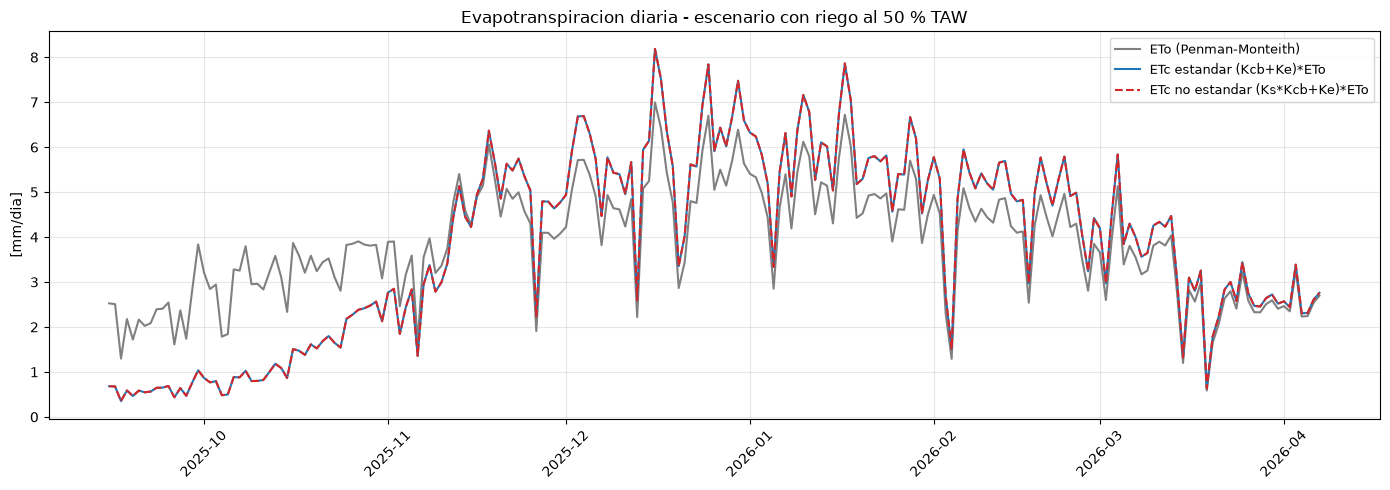

In [14]:
# CELDA 10 - Grafico: ETo y ETc diaria (estandar vs no estandar)

fig, ax = plt.subplots(figsize=(14, 5))
x = res['fecha']

ax.plot(x, res['ETo'], label='ETo (Penman-Monteith)', color='gray')
ax.plot(x, res['ETc_estandar_mm_d'],
        label='ETc estandar (Kcb+Ke)*ETo', color='tab:blue')
ax.plot(x, res['ETc_no_estandar_mm_d'],
        label='ETc no estandar (Ks*Kcb+Ke)*ETo',
        color='tab:red', linestyle='--')

ax.set_ylabel('[mm/dia]')
ax.set_title('Evapotranspiracion diaria - escenario con riego al 50 % TAW')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


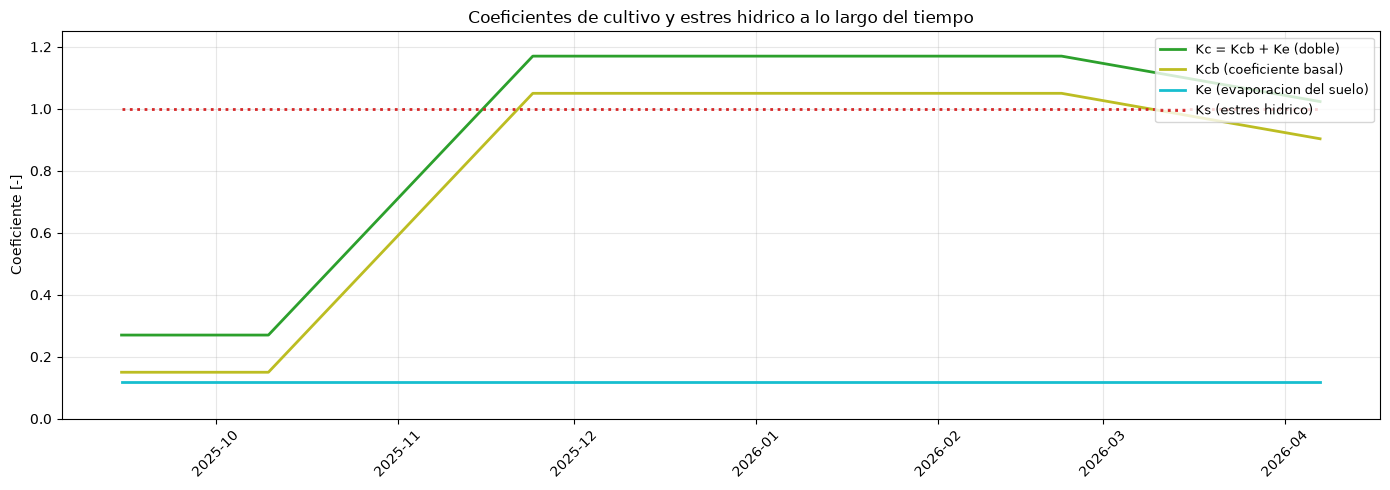

In [15]:
# CELDA 11 - Grafico: Kc y Kcb en la temporada

fig, ax = plt.subplots(figsize=(14, 5))
x = res['fecha']

ax.plot(x, res['Kc'], label='Kc = Kcb + Ke (doble)',
        color='tab:green', linewidth=2)
ax.plot(x, res['Kcb'], label='Kcb (coeficiente basal)',
        color='tab:olive', linewidth=2)
ax.plot(x, res['Ke'], label='Ke (evaporacion del suelo)',
        color='tab:cyan', linewidth=2)
ax.plot(x, res['Ks'], label='Ks (estres hidrico)',
        color='tab:red', linestyle=':', linewidth=2)

ax.set_ylabel('Coeficiente [-]')
ax.set_title('Coeficientes de cultivo y estres hidrico a lo largo del tiempo')
ax.legend(fontsize=9, loc='upper right')
ax.grid(alpha=0.3)
ax.set_ylim(0, 1.25)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


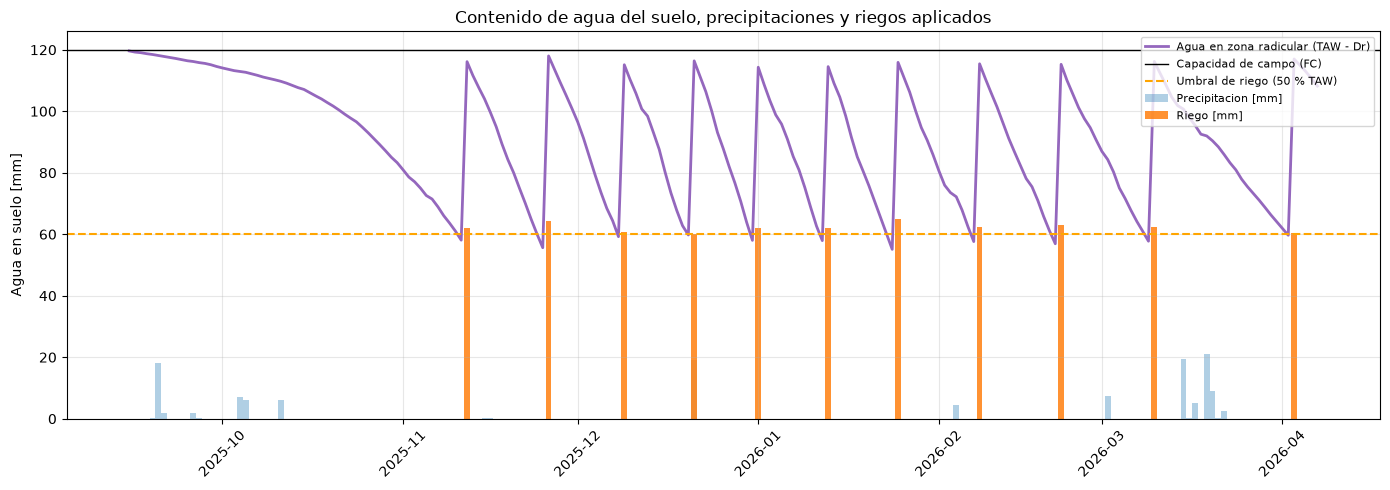

In [16]:
# CELDA 12 - Grafico: Contenido de agua del suelo, riegos y precipitaciones

TAW = 1000.0 * (cs.th_FC - cs.th_WP) * cs.Zr

fig, ax = plt.subplots(figsize=(14, 5))
x = res['fecha']

contenido_agua = TAW - res['Dr_mm']
ax.plot(x, contenido_agua, label='Agua en zona radicular (TAW - Dr)',
        color='tab:purple', linewidth=2)

ax.axhline(TAW, color='black', linestyle='-', linewidth=1,
           label='Capacidad de campo (FC)')
ax.axhline(0.5 * TAW, color='orange', linestyle='--', linewidth=1.5,
           label='Umbral de riego (50 % TAW)')

ax.bar(x, res['P_mm'], width=1.0, alpha=0.35,
       label='Precipitacion [mm]', color='tab:blue')
riego_dias = res['riego_mm'] > 0
if riego_dias.any():
    ax.bar(x[riego_dias], res.loc[riego_dias, 'riego_mm'], width=1.0,
           alpha=0.85, label='Riego [mm]', color='tab:orange')

ax.set_ylabel('Agua en suelo [mm]')
ax.set_title('Contenido de agua del suelo, precipitaciones y riegos aplicados')
ax.legend(fontsize=8, loc='upper right')
ax.grid(alpha=0.3)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


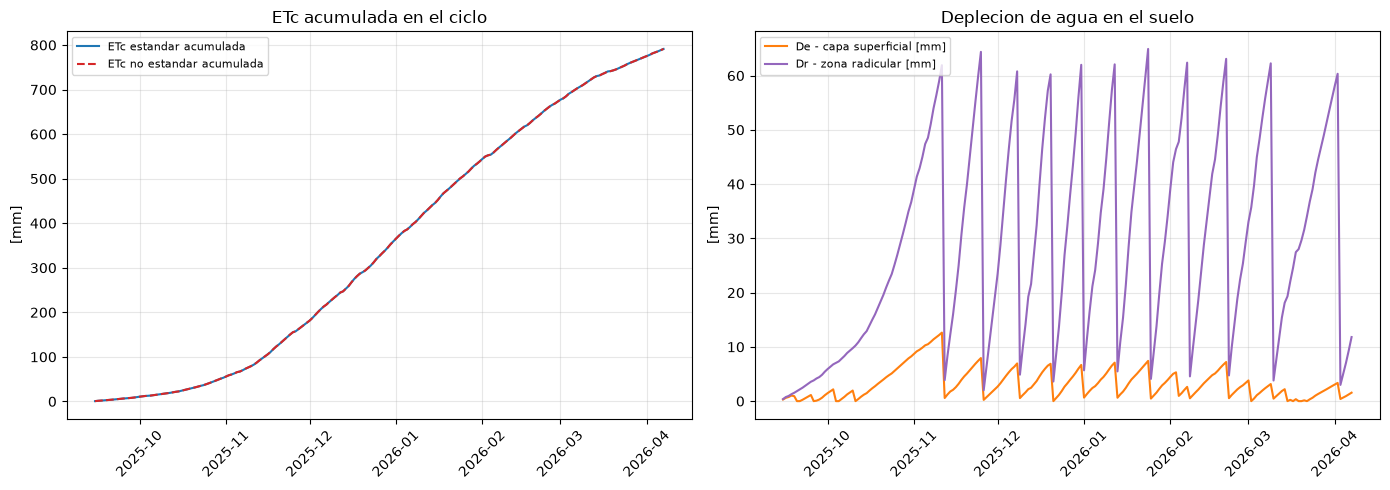

In [17]:
# CELDA 13 - Grafico: ETc acumulada y deplecion del suelo

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
x = res['fecha']

# Izquierda: ETc acumulada
axs[0].plot(x, res['ETc_estandar_cum_mm'], label='ETc estandar acumulada',
            color='tab:blue')
axs[0].plot(x, res['ETc_no_estandar_cum_mm'], label='ETc no estandar acumulada',
            color='tab:red', linestyle='--')
axs[0].set_ylabel('[mm]')
axs[0].set_title('ETc acumulada en el ciclo')
axs[0].legend(fontsize=8)
axs[0].grid(alpha=0.3)
axs[0].tick_params(axis='x', rotation=45)

# Derecha: deplecion
axs[1].plot(x, res['De_mm'], label='De - capa superficial [mm]', color='tab:orange')
axs[1].plot(x, res['Dr_mm'], label='Dr - zona radicular [mm]', color='tab:purple')
axs[1].set_ylabel('[mm]')
axs[1].set_title('Deplecion de agua en el suelo')
axs[1].legend(fontsize=8)
axs[1].grid(alpha=0.3)
axs[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## Conclusión

Con riego al 50 % de TAW (reposicion a capacidad de campo), el cultivo no sufre estres hidrico (Ks aprox. 1 todo el ciclo), por lo que ETc estandar aproximadamente igual a ETc no estandar.

- Los archivos se guardan en `Proyecto_Final/`:
  - `resultados_ETc_escenario_riego.csv` - serie diaria completa.
  - Las 4 figuras se muestran arriba y se pueden exportar como PNG desde el menu   File -> Save as de Jupyter.

> Para ejecutar este cuaderno: `jupyter notebook Proyecto_ETc_FAO56_Cuaderno.ipynb`
